## Practical Homework 1 - Linear Regression

**Please write your name and student number in the following cell.**

In [62]:
# Student_Name = "ShayanPourmasoomi"
# Student_Number = "403201483"

## Phase 0: Intro

For this assignment, you'll be given a dataset containing cars for sale. To study the dataset in more detail, refer to [this](https://www.kaggle.com/datasets/arianghasemi/divar-cars/data) link.

In [63]:
!wget -O /kaggle/working/dataset.csv "https://www.dropbox.com/scl/fi/cwd3e0wo7j41wungb4zat/cars.csv?rlkey=z83jkj9ex2no06z4htf6ce1w5&dl=1"

/kaggle/working/dataset.csv: No such file or directory


In [64]:
!wget -O dataset.csv "https://www.dropbox.com/scl/fi/cwd3e0wo7j41wungb4zat/cars.csv?rlkey=z83jkj9ex2no06z4htf6ce1w5&dl=1"


--2025-11-14 12:10:58--  https://www.dropbox.com/scl/fi/cwd3e0wo7j41wungb4zat/cars.csv?rlkey=z83jkj9ex2no06z4htf6ce1w5&dl=1
Resolving www.dropbox.com (www.dropbox.com)... 162.125.3.18, 2620:100:6018:18::a27d:312
Connecting to www.dropbox.com (www.dropbox.com)|162.125.3.18|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://ucfe40e74fc91356368f43f114c1.dl.dropboxusercontent.com/cd/0/inline/C1LR1JWu28rapdHU-cy_9KX_krZ-DW52dMlrNYh8xheew5OsceTm0rY9beLVzed4WuIG_Oqj5BJlqcFBkgWzAWWbYU3gR8wMfOZFmXDYbfQX4XJP8Lwzt94qO1kmitX1N6Z76oo-443nlRxHCFhFfJCF/file?dl=1# [following]
--2025-11-14 12:10:58--  https://ucfe40e74fc91356368f43f114c1.dl.dropboxusercontent.com/cd/0/inline/C1LR1JWu28rapdHU-cy_9KX_krZ-DW52dMlrNYh8xheew5OsceTm0rY9beLVzed4WuIG_Oqj5BJlqcFBkgWzAWWbYU3gR8wMfOZFmXDYbfQX4XJP8Lwzt94qO1kmitX1N6Z76oo-443nlRxHCFhFfJCF/file?dl=1
Resolving ucfe40e74fc91356368f43f114c1.dl.dropboxusercontent.com (ucfe40e74fc91356368f43f114c1.dl.dropboxusercontent.com)... 162.125.3

In [65]:
# Warning! You are not permitted to import any other libraries
import re
import os
import pandas
import sklearn
import numpy as np
import pandas as pd

from tqdm import tqdm

import seaborn as sns
from joblib import dump, load
import seaborn as sns
from matplotlib import pyplot as plt

import warnings
from warnings import simplefilter
simplefilter(action="ignore", category=pd.errors.PerformanceWarning)
warnings.filterwarnings("ignore", "is_categorical_dtype")
warnings.filterwarnings("ignore", "use_inf_as_na")

## Phase 1: Load Data (P1: 2 points)

Load the dataset (as a dataframe) using pandas and display the top 5 rows of the dataframe. **(P1-1: 1 points)**

In [66]:
df = pd.read_csv('dataset.csv')
df.head()

,City,Model_Year,Color,Mileage,Brand,Body_Condition,Price,Engine_Condition,Chassis_Condition,Third_party_insurance,Gearbox,Selling_Method,Time,Location
0,Tehran,۱۳۷۶,نقره ای,۵۳۲,نیسان، پاترول 4 در، 6 سیلندر,تمام رنگ,235000000.0,سالم,سالم و پلمپ,۶ ماه,دنده ای,نقدی,2022-03-26,آجودانیه
1,Tehran,۱۳۹۲,سفید,۱۵۰٬۰۰۰,CNG ،پیکان، وانت,خط و خش جزیی,110000000.0,NaN,NaN,NaN,NaN,NaN,2022-03-12,بلوار کشاورز
2,Tehran,۱۳۹۹,سفید,۰,SE ،131 ،پراید,سالم و بی خط و خش,NaN,NaN,سالم و پلمپ,۱۲ ماه,NaN,نقدی,2022-03-26,دولت آباد
3,Tehran,۱۳۹۶,سفید,۸۰٬۰۰۰,SE ،132 ،پراید,سالم و بی خط و خش,125500000.0,سالم,سالم و پلمپ,۶ ماه,دنده ای,نقدی,2022-03-26,پیروزی
4,Tehran,۱۳۹۳,نقره ای,۸۰٬۰۰۰,پژو، GLX ،405 بنزینی,سالم و بی خط و خش,187000000.0,سالم,سالم و پلمپ,۹ ماه,دنده ای,نقدی,2022-03-26,پیروزی


فایل داده ها به صورت یک دیتا فریم بارگذاری میکند و ۵ ردیف اول را نشان می دهد .


Drop any row containing null values. **(P1-2: 1 points)**

In [67]:

df.dropna(inplace=True)
df.head()

,City,Model_Year,Color,Mileage,Brand,Body_Condition,Price,Engine_Condition,Chassis_Condition,Third_party_insurance,Gearbox,Selling_Method,Time,Location
0,Tehran,۱۳۷۶,نقره ای,۵۳۲,نیسان، پاترول 4 در، 6 سیلندر,تمام رنگ,235000000.0,سالم,سالم و پلمپ,۶ ماه,دنده ای,نقدی,2022-03-26,آجودانیه
3,Tehran,۱۳۹۶,سفید,۸۰٬۰۰۰,SE ،132 ،پراید,سالم و بی خط و خش,125500000.0,سالم,سالم و پلمپ,۶ ماه,دنده ای,نقدی,2022-03-26,پیروزی
4,Tehran,۱۳۹۳,نقره ای,۸۰٬۰۰۰,پژو، GLX ،405 بنزینی,سالم و بی خط و خش,187000000.0,سالم,سالم و پلمپ,۹ ماه,دنده ای,نقدی,2022-03-26,پیروزی
5,Tehran,۱۳۹۳,سفید,۸۵٬۰۰۰,SD، V8 206 ،پژو,خط و خش جزیی,215000000.0,سالم,سالم و پلمپ,۴ ماه,دنده ای,نقدی,2022-03-05,یوسف آباد
9,Tehran,۲۰۱۶,سفید,۱۰۰٬۰۰۰,سانگ یانگ، تیوولی، الیت,سالم و بی خط و خش,830000000.0,سالم,سالم و پلمپ,۸ ماه,اتوماتیک,نقدی,2022-03-26,وردآورد


تمامی داده های خالی را دراپ میکنید (ردیف) و دیتا فریم جدید را بدون دیتا ها خالی نشان میدهد .

## Phase 2: Preprocess (P2: 18 points)

Print names of the columns and the number of rows in the dataset. **(P2-1: 1 points)**

In [68]:

print("Column Names:", df.columns.tolist())
print("Number of Rows:", len(df))


Column Names: ['City', 'Model_Year', 'Color', 'Mileage', 'Brand', 'Body_Condition', 'Price', 'Engine_Condition', 'Chassis_Condition', 'Third_party_insurance', 'Gearbox', 'Selling_Method', 'Time', 'Location']
Number of Rows: 32725


لیست نام همهٔ ستون‌ها را چاپ می‌کند و تعداد کل ردیف‌های موجود در دیتاست (بعد از حذف مقادیر خالی) را نمایش می‌دهد.

Drop all rows where "Selling_Method" is not "نقدی", and then drop the columns "Selling_Method", "Time" and "Location". **(P2-2: 1 points)**

In [69]:


df = df[df['Selling_Method'] == 'نقدی']

df = df.drop(['Selling_Method' , 'Time' , 'Location'], axis=1)


df.head()


,City,Model_Year,Color,Mileage,Brand,Body_Condition,Price,Engine_Condition,Chassis_Condition,Third_party_insurance,Gearbox
0,Tehran,۱۳۷۶,نقره ای,۵۳۲,نیسان، پاترول 4 در، 6 سیلندر,تمام رنگ,235000000.0,سالم,سالم و پلمپ,۶ ماه,دنده ای
3,Tehran,۱۳۹۶,سفید,۸۰٬۰۰۰,SE ،132 ،پراید,سالم و بی خط و خش,125500000.0,سالم,سالم و پلمپ,۶ ماه,دنده ای
4,Tehran,۱۳۹۳,نقره ای,۸۰٬۰۰۰,پژو، GLX ،405 بنزینی,سالم و بی خط و خش,187000000.0,سالم,سالم و پلمپ,۹ ماه,دنده ای
5,Tehran,۱۳۹۳,سفید,۸۵٬۰۰۰,SD، V8 206 ،پژو,خط و خش جزیی,215000000.0,سالم,سالم و پلمپ,۴ ماه,دنده ای
9,Tehran,۲۰۱۶,سفید,۱۰۰٬۰۰۰,سانگ یانگ، تیوولی، الیت,سالم و بی خط و خش,830000000.0,سالم,سالم و پلمپ,۸ ماه,اتوماتیک


در اینجا تمامی روش های فروش غیر نقدی (ردیف) و بعد از ان ستون های زمان روش فروش ، مکان حذف میشوند .

Retrieve the description of all columns in the dataset. **(P2-3: 1 points)**

In [70]:

print(df.info())


print(df.describe(include='all'))

<class 'pandas.core.frame.DataFrame'>
Index: 31880 entries, 0 to 56401
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   City                   31880 non-null  object 
 1   Model_Year             31880 non-null  object 
 2   Color                  31880 non-null  object 
 3   Mileage                31880 non-null  object 
 4   Brand                  31880 non-null  object 
 5   Body_Condition         31880 non-null  object 
 6   Price                  31880 non-null  float64
 7   Engine_Condition       31880 non-null  object 
 8   Chassis_Condition      31880 non-null  object 
 9   Third_party_insurance  31880 non-null  object 
 10  Gearbox                31880 non-null  object 
dtypes: float64(1), object(10)
memory usage: 2.9+ MB
None
          City Model_Year  Color Mileage           Brand     Body_Condition  \
count    31880      31880  31880   31880           31880              31880   
uniq

ساختار دیتاست (نوع داده هر ستون، تعداد مقادیر غیر خالی) را نمایش می‌دهد و سپس خلاصهٔ آماری کامل تمام ستون‌ها (عددی و غیرعددی) را چاپ می‌کند.

**We need to perform some operations on certain columns to make the entire dataset suitable for a Linear Regression task.**

Change the 'Model_Year' type to numerical. Convert all years written in the Gregorian format to the Solar format. Then, take 1365 as the start year and count the number of years passed since 1365. For example, the year 1399 must be substituted with 34, and the cars tagged with 'قبل از ۱۳۶۶' must be substituted with 0. **(P2-4: 3 points)**

In [71]:
def change_to_solar(date):
    if isinstance(date, str) and 'قبل' in date:
        return 0

    try:
        year = int(date)
    except:
        return None

    if year > 1900:
        year -= 621

    return year - 1365

df['Model_Year'] = df['Model_Year'].apply(change_to_solar)


این تابع سال را از حالت میلادی به شمسی تبدیل می‌کند، سپس فاصلهٔ آن از سال ۱۳۶۵ را محاسبه می‌کند و اگر سال قبل از ۱۳۶۵ باشد مقدار ۰ برمی‌گرداند.

Change the types of 'Mileage' and 'Third_party_insurance' to numerical. **(P2-5: 1 points)**

In [72]:

def to_english_digits(text):
    if pd.isna(text):
        return text
    s = str(text)

    persian_digits = '۰۱۲۳۴۵۶۷۸۹'
    arabic_digits  = '٠١٢٣٤٥٦٧٨٩'
    english_digits = '0123456789'

    for p, e in zip(persian_digits, english_digits):
        s = s.replace(p, e)
    for a, e in zip(arabic_digits, english_digits):
        s = s.replace(a, e)
    return s


def strip_thousands_and_spaces(s):
    return s.replace(',', '').replace('،', '').replace('٬', '').strip()


def clean_mileage(x):
    if pd.isna(x):
        return np.nan
    s = to_english_digits(x)
    s = strip_thousands_and_spaces(s)

    s = re.sub(r'[^0-9.]', '', s)
    return pd.to_numeric(s, errors='coerce')


def parse_insurance_to_months(x):
    if pd.isna(x):
        return np.nan
    s = to_english_digits(x)
    s = strip_thousands_and_spaces(s).lower()


    if any(word in s for word in ['ندارد', 'تمام', 'پایان', 'انقضا', 'بدون', 'نامشخص']):
        return 0


    m = re.search(r'(\d+(?:\.\d+)?)', s)
    if not m:
        return np.nan
    val = float(m.group(1))


    if 'سال' in s:
        months = val * 12
    elif 'ماه' in s:
        months = val
    elif 'روز' in s:
        months = val / 30.0
    else:

        months = val

    return months


df['Mileage'] = df['Mileage'].apply(clean_mileage)

df['Third_party_insurance'] = df['Third_party_insurance'].apply(parse_insurance_to_months)
df['Third_party_insurance'] = pd.to_numeric(df['Third_party_insurance'], errors='coerce')

print(df[['Mileage', 'Third_party_insurance']].head())
print(df[['Mileage', 'Third_party_insurance']].dtypes)


   Mileage  Third_party_insurance
0      532                    6.0
3    80000                    6.0
4    80000                    9.0
5    85000                    4.0
9   100000                    8.0
Mileage                    int64
Third_party_insurance    float64
dtype: object


اعداد فارسی و عربی را به اعداد انگلیسی تبدیل می‌کند تا پردازش عددی راحت‌تر انجام شود.
ویرگول، جداکننده هزارگان و فاصلهٔ اضافی را از رشتهٔ عددی حذف می‌کند.
کیلومتر خودرو را از حالت رشته‌ای، شامل کاراکترها و جداکننده‌ها، به عدد پاک و قابل محاسبه تبدیل می‌کند.
مقدار بیمه شخص ثالث (مثل "۱۲ ماه") را استخراج کرده و به عدد ماه تبدیل می‌کند.

For 'Engine_Condition', map 'سالم' to 2, 'تعویض شده' to 1, and 'نیاز به تعمیر' to 0. **(P2-6: 2 points)**

In [73]:
ENGINE_WORKING = "سالم"
ENGINE_SUBSTITUTED = "تعویض شده"
ENGINE_NEEDS_TO_BE_FIXED = "نیاز به تعمیر"
engine_condition_map = {
    ENGINE_WORKING: 2,
    ENGINE_SUBSTITUTED: 1,
    ENGINE_NEEDS_TO_BE_FIXED: 0
}

df['Engine_Condition'] = df['Engine_Condition'].map(engine_condition_map)


In [74]:
df['Engine_Condition'].unique()


array([2, 0, 1])

وضعیت موتور را به مقادیر عددی تبدیل می‌کند: سالم = ۲، تعویض شده = ۱ و نیاز به تعمیر = ۰، تا برای مدل رگرسیون قابل استفاده شود.

For 'Chassis_Condition', map 'سالم و پلمپ' to 2, 'ضربه خورده' to 1, and 'رنگ شده' to 0. **(P2-7: 1 points)**


In [75]:
CHASSIS_WORKING = "سالم و پلمپ"
CHASSIS_SUBSTITUTED = "ضربه خورده"
CHASSIS_NEEDS_TO_BE_FIXED = "رنگ شده"
chassis_condition_map = {
    CHASSIS_WORKING: 2,
    CHASSIS_SUBSTITUTED: 1,
    CHASSIS_NEEDS_TO_BE_FIXED: 0
}

df['Chassis_Condition'] = df['Chassis_Condition'].map(chassis_condition_map)

In [76]:

df['Chassis_Condition'].unique()

array([2, 1, 0])

وضعیت شاسی خودرو را نیز مشابه موتور به مقادیر عددی (۲، ۱، ۰) تبدیل می‌کند تا داده‌ها برای یادگیری ماشین عددی شوند.

For 'Gearbox', map 'دنده ای' to 0 and 'اتوماتیک' to 1. **(P2-8: 1 points)**

In [77]:
GEARBOX_MANUAL = "دنده ای"
GEARBOX_AUTO = "اتوماتیک"
gearbox_map = {
    GEARBOX_AUTO: 1,
    GEARBOX_MANUAL: 0
}
df['Gearbox'] = df['Gearbox'].map(gearbox_map)

In [78]:
df['Gearbox'].unique()

array([0, 1])

همانند بالا برای. گیربکس ماشین عمل میکند

Convert the "City" column into one-hot format. Then drop the "City" column. You will need to create a column for each unique City, and in each row, the column corresponding to its City will be 1, and other columns will be 0. **(P2-9: 2 points)**

In [79]:
city_dummies = pd.get_dummies(df['City'], prefix='City' , dtype=int)

df = pd.concat([df, city_dummies], axis=1)

df = df.drop('City', axis=1)

df.head()


,Model_Year,Color,Mileage,Brand,Body_Condition,Price,Engine_Condition,Chassis_Condition,Third_party_insurance,Gearbox,City_Isfahan,City_Mashhad,City_Shiraz,City_Tehran
0,11,نقره ای,532,نیسان، پاترول 4 در، 6 سیلندر,تمام رنگ,235000000.0,2,2,6.0,0,0,0,0,1
3,31,سفید,80000,SE ،132 ،پراید,سالم و بی خط و خش,125500000.0,2,2,6.0,0,0,0,0,1
4,28,نقره ای,80000,پژو، GLX ،405 بنزینی,سالم و بی خط و خش,187000000.0,2,2,9.0,0,0,0,0,1
5,28,سفید,85000,SD، V8 206 ،پژو,خط و خش جزیی,215000000.0,2,2,4.0,0,0,0,0,1
9,30,سفید,100000,سانگ یانگ، تیوولی، الیت,سالم و بی خط و خش,830000000.0,2,2,8.0,1,0,0,0,1


این کد ستون City را به چند ستون باینری (۰/۱) تبدیل می‌کند که هر ستون نشان‌دهندهٔ یک شهر است، سپس ستون اصلی City حذف می‌شود.

Do the same steps for "Color" and "Body_Condition" columns **(P2-10: 2 points)**

In [80]:

color_dummies = pd.get_dummies(df['Color'], prefix='Color', dtype=int)

body_dummies = pd.get_dummies(df['Body_Condition'], prefix='Body', dtype=int)

df = pd.concat([df, color_dummies, body_dummies], axis=1)

df = df.drop(['Color', 'Body_Condition'], axis=1)

df.head()


,Model_Year,Mileage,Brand,Price,Engine_Condition,Chassis_Condition,Third_party_insurance,Gearbox,City_Isfahan,City_Mashhad,...,Body_سالم و بی خط و خش,Body_صافکاری بی رنگ,Body_صافکاری بی رنگ، در ۱ ناحیه,Body_صافکاری بی رنگ، در ۱۰ ناحیه,Body_صافکاری بی رنگ، در ۲ ناحیه,Body_صافکاری بی رنگ، در ۳ ناحیه,Body_صافکاری بی رنگ، در ۴ ناحیه,Body_صافکاری بی رنگ، در ۵ ناحیه,Body_صافکاری بی رنگ، در ۶ ناحیه,Body_صافکاری بی رنگ، در ۹ ناحیه
0,11,532,نیسان، پاترول 4 در، 6 سیلندر,235000000.0,2,2,6.0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,31,80000,SE ،132 ،پراید,125500000.0,2,2,6.0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
4,28,80000,پژو، GLX ،405 بنزینی,187000000.0,2,2,9.0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
5,28,85000,SD، V8 206 ،پژو,215000000.0,2,2,4.0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9,30,100000,سانگ یانگ، تیوولی، الیت,830000000.0,2,2,8.0,1,0,0,...,1,0,0,0,0,0,0,0,0,0


در این قسمت ستون‌های رنگ خودرو و وضعیت بدنه به صورت وان هات به ستون‌های عددی تبدیل می‌شوند، سپس ستون‌های متنی اصلی حذف می‌گردند.

Up until now, you have learned how to clean such a dataset. now, let's take other cars aside and focus on the "Pride". drop all the items in the dataframe where the "Brand" does not contain "پراید" and drop the "Brand" column **(P2-11: 3 points)**

In [82]:

df = df[df['Brand'].str.contains('پراید', na=False)]

df = df.drop('Brand', axis=1)


df.head()


,Model_Year,Mileage,Price,Engine_Condition,Chassis_Condition,Third_party_insurance,Gearbox,City_Isfahan,City_Mashhad,City_Shiraz,...,Body_سالم و بی خط و خش,Body_صافکاری بی رنگ,Body_صافکاری بی رنگ، در ۱ ناحیه,Body_صافکاری بی رنگ، در ۱۰ ناحیه,Body_صافکاری بی رنگ، در ۲ ناحیه,Body_صافکاری بی رنگ، در ۳ ناحیه,Body_صافکاری بی رنگ، در ۴ ناحیه,Body_صافکاری بی رنگ، در ۵ ناحیه,Body_صافکاری بی رنگ، در ۶ ناحیه,Body_صافکاری بی رنگ، در ۹ ناحیه
3,31,80000,125500000.0,2,2,6.0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
12,31,80000,135000000.0,2,2,11.0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
21,28,300000,110000000.0,2,2,6.0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
46,33,40000,152000000.0,2,2,10.0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
63,32,42000,145000000.0,2,2,6.0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0


این کد فقط ردیف‌هایی را نگه می‌دارد که برند آن‌ها «پراید» است و سپس ستون برند را حذف می‌کند چون دیگر به آن نیازی نیست.

## Phase 3: Exploration (P3: 10 points)

In [83]:
df.head()

,Model_Year,Mileage,Price,Engine_Condition,Chassis_Condition,Third_party_insurance,Gearbox,City_Isfahan,City_Mashhad,City_Shiraz,...,Body_سالم و بی خط و خش,Body_صافکاری بی رنگ,Body_صافکاری بی رنگ، در ۱ ناحیه,Body_صافکاری بی رنگ، در ۱۰ ناحیه,Body_صافکاری بی رنگ، در ۲ ناحیه,Body_صافکاری بی رنگ، در ۳ ناحیه,Body_صافکاری بی رنگ، در ۴ ناحیه,Body_صافکاری بی رنگ، در ۵ ناحیه,Body_صافکاری بی رنگ، در ۶ ناحیه,Body_صافکاری بی رنگ، در ۹ ناحیه
3,31,80000,125500000.0,2,2,6.0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
12,31,80000,135000000.0,2,2,11.0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
21,28,300000,110000000.0,2,2,6.0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
46,33,40000,152000000.0,2,2,10.0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
63,32,42000,145000000.0,2,2,6.0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0


Create **a copy** of the first 7 columns of the dataframe (We won't visualize the one-hot features. so we don't need them). **(P3-1: 2 points)**

In [84]:
df_small = df.iloc[:, :7].copy()

یک کپی از ۷ ستون اول دیتافریم ایجاد می‌شود تا برای تحلیل‌های تصویری  که به ویژگی‌های وان هات نیازی ندارند، استفاده شود.

In [85]:
df_small.head()

,Model_Year,Mileage,Price,Engine_Condition,Chassis_Condition,Third_party_insurance,Gearbox
3,31,80000,125500000.0,2,2,6.0,0
12,31,80000,135000000.0,2,2,11.0,0
21,28,300000,110000000.0,2,2,6.0,0
46,33,40000,152000000.0,2,2,10.0,0
63,32,42000,145000000.0,2,2,6.0,0


Utilize histograms and box plots to visualize the distribution of the  **(P3-2: 5 points)**

<Figure size 1500x800 with 0 Axes>

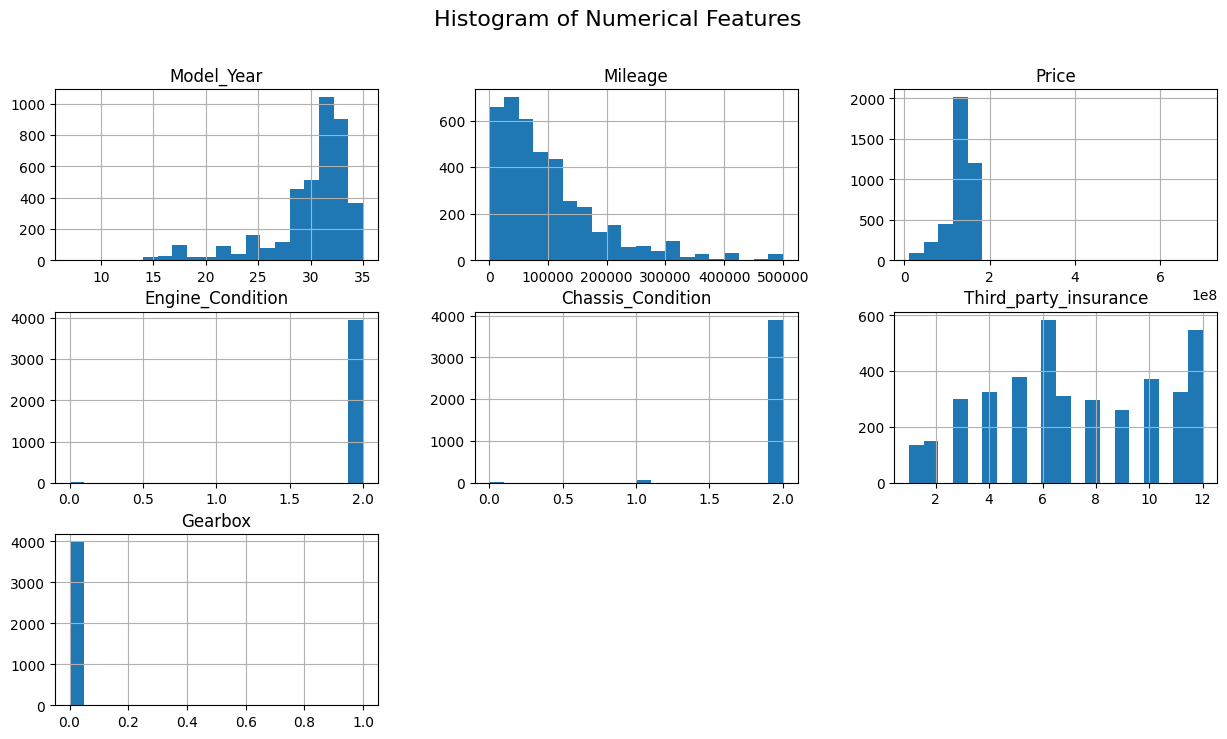

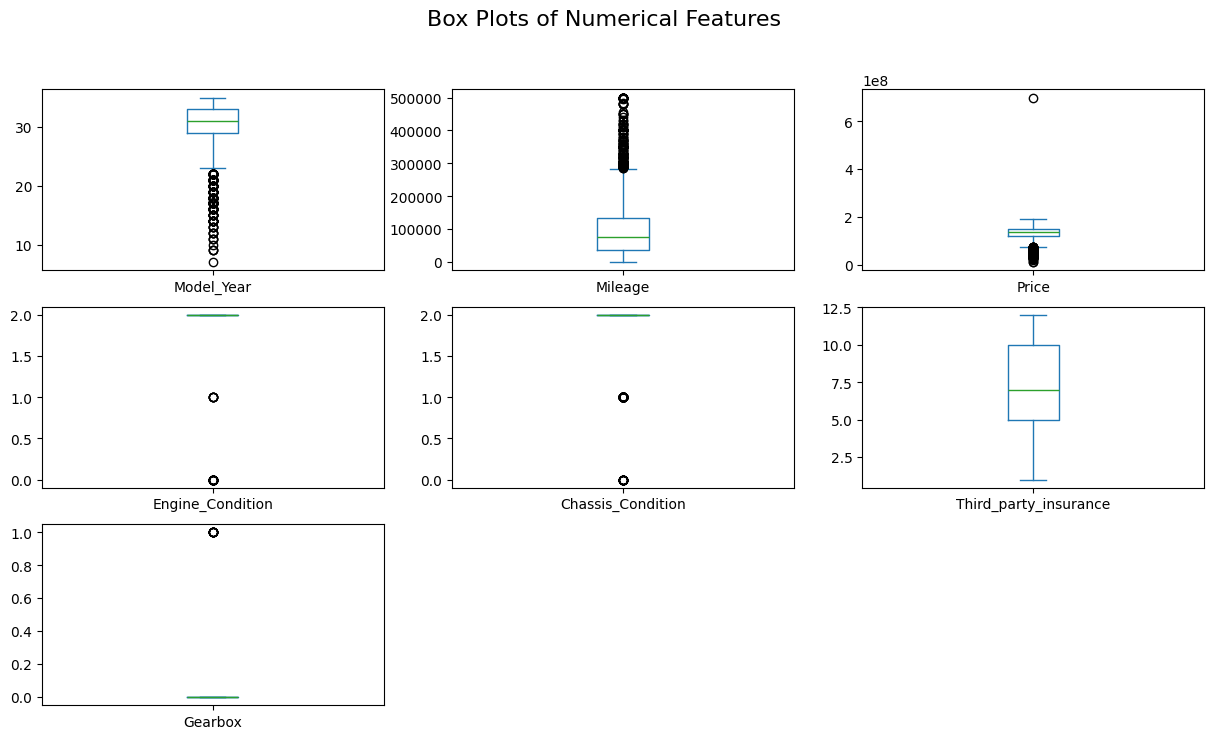

In [86]:
plt.figure(figsize=(15, 8))

df_small.hist(bins=20, figsize=(15, 8))
plt.suptitle("Histogram of Numerical Features", fontsize=16)
plt.show()

df_small.plot(kind='box', subplots=True, layout=(3, 3), figsize=(15, 8), sharex=False, sharey=False)
plt.suptitle("Box Plots of Numerical Features", fontsize=16)
plt.show()

Print the correlation coefficients matrix **(P3-3: 1 points)**

In [87]:

corr_matrix = df_small.corr()
print(corr_matrix)

                       Model_Year   Mileage     Price  Engine_Condition  \
Model_Year               1.000000 -0.660337  0.890160          0.186486   
Mileage                 -0.660337  1.000000 -0.651101         -0.081709   
Price                    0.890160 -0.651101  1.000000          0.183401   
Engine_Condition         0.186486 -0.081709  0.183401          1.000000   
Chassis_Condition        0.260769 -0.168138  0.281417          0.093159   
Third_party_insurance   -0.012934 -0.003465  0.002169          0.009234   
Gearbox                 -0.090999  0.026115 -0.043853          0.004352   

                       Chassis_Condition  Third_party_insurance   Gearbox  
Model_Year                      0.260769              -0.012934 -0.090999  
Mileage                        -0.168138              -0.003465  0.026115  
Price                           0.281417               0.002169 -0.043853  
Engine_Condition                0.093159               0.009234  0.004352  
Chassis_Condition  

این کد ماتریس همبستگی بین ویژگی‌های عددی موجود در دیتا فریم جدید را محاسبه و چاپ می‌کند تا مشخص شود کدام ویژگی‌ها با یکدیگر رابطه قوی دارند.

Plot `Price` plot according to`Mileage` using `seaborn.scatterplot` **(P3-4: 1 points)**

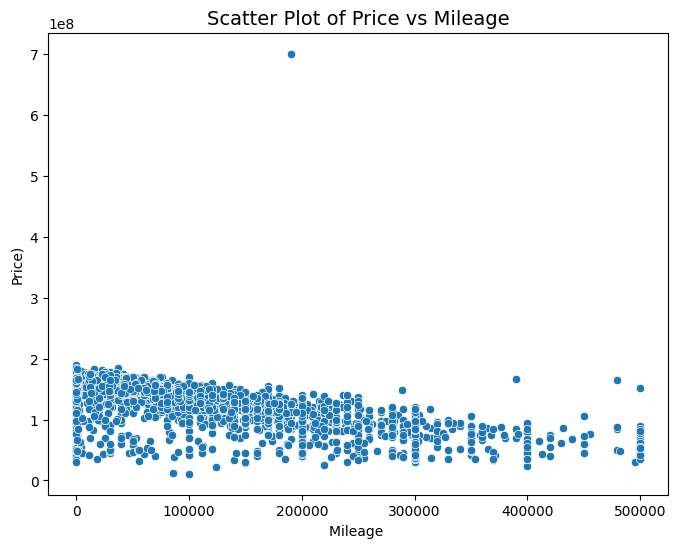

In [88]:

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='Mileage', y='Price')

plt.title('Scatter Plot of Price vs Mileage', fontsize=14)
plt.xlabel('Mileage ')
plt.ylabel('Price)')

plt.show()

نمودار پراکندگی قیمت خودرو را نسبت به میزان کارکرد  نمایش می‌دهد تا رابطهٔ تصویری بین این دو متغیر بررسی شود.

Plot `Model_Year` plot according to`Gearbox` using `seaborn.lineplot` **(P3-5: 1 points)**

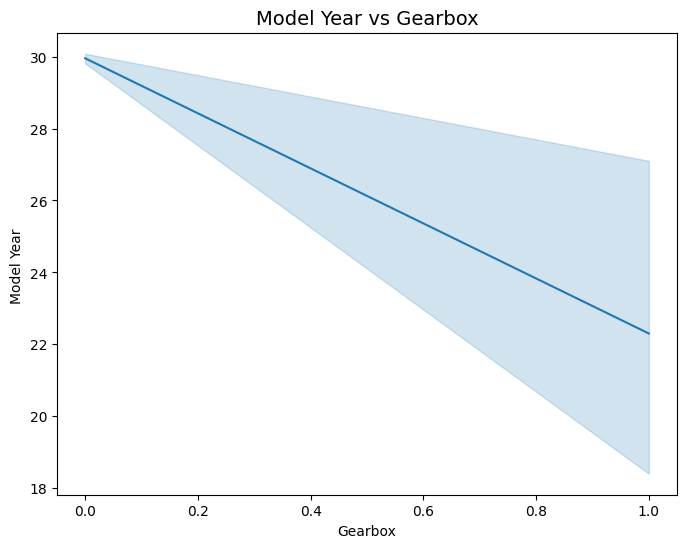

In [89]:

plt.figure(figsize=(8, 6))

sns.lineplot(data=df, x='Gearbox', y='Model_Year')

plt.title('Model Year vs Gearbox', fontsize=14)
plt.xlabel('Gearbox')
plt.ylabel('Model Year ')

plt.show()

این نمودار خطی روند تغییرات سال ساخت  را نسبت به نوع گیربکس  نشان می‌دهد تا تفاوت میان خودروهای دنده‌ای و اتوماتیک بررسی شود.

It's clear that some columns are more correlated with the price. In practice, when dealing with many columns, we might set aside the least correlated ones and focus on the rest. However, here we will continue with all columns of 'df'.

## Phase 4: Training (P4: 55 points)

### Sec 1: Preparing features and Targets (P4-Sec1: 10 points)

Extract only the features from the dataframe by removing the target column ("Price").
Note: Do not remove the previous dataframe. **(P4-1-1: 2 points)**

In [90]:


X = df_small.drop('Price', axis=1)

X.head()


,Model_Year,Mileage,Engine_Condition,Chassis_Condition,Third_party_insurance,Gearbox
3,31,80000,2,2,6.0,0
12,31,80000,2,2,11.0,0
21,28,300000,2,2,6.0,0
46,33,40000,2,2,10.0,0
63,32,42000,2,2,6.0,0


این کد ستون قیمت را حذف می‌کند تا فقط ویژگی‌های ورودی مدل باقی بمانند و آن‌ها را در ایکس ذخیره می‌کند.

Convert the new dataframe into a numpy array. **(P4-1-2: 1 points)**

In [91]:
X_array = X.to_numpy()

print("Shape of X_array:", X_array.shape)

print(X_array[:5])


Shape of X_array: (3987, 6)
[[3.1e+01 8.0e+04 2.0e+00 2.0e+00 6.0e+00 0.0e+00]
 [3.1e+01 8.0e+04 2.0e+00 2.0e+00 1.1e+01 0.0e+00]
 [2.8e+01 3.0e+05 2.0e+00 2.0e+00 6.0e+00 0.0e+00]
 [3.3e+01 4.0e+04 2.0e+00 2.0e+00 1.0e+01 0.0e+00]
 [3.2e+01 4.2e+04 2.0e+00 2.0e+00 6.0e+00 0.0e+00]]


ویژگی‌ها از قالب دیتافریم به آرایهٔ نامپای تبدیل می‌شوند تا در الگوریتم‌های رگرسیون قابل استفاده باشند؛ همچنین شکل ماتریس ایکس چاپ می‌شود.

Get the target column from the previous dataframe and convert it to another numpy array named y **(P4-1-3: 1 points)**

In [92]:

y = df_small['Price'].to_numpy()

print("Shape of y:", y.shape)

print(y[:10])


Shape of y: (3987,)
[1.255e+08 1.350e+08 1.100e+08 1.520e+08 1.450e+08 1.560e+08 1.530e+08
 1.300e+08 9.700e+07 9.000e+07]


ستون قیمت به‌عنوان متغیر هدف استخراج شده و به یک بردار نامپای تبدیل می‌شود تا برای آموزش مدل رگرسیونی آماده گردد.

Split the dataset into two parts such that the training set (denoted a`x_train` and `y_train`), contains 80% of the samples. **(P4-1-4: 3 points)**

In [93]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(
    X_array, y, test_size=0.2, random_state=42
)

print("x_train shape:", x_train.shape)
print("x_test shape:", x_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)


x_train shape: (3189, 6)
x_test shape: (798, 6)
y_train shape: (3189,)
y_test shape: (798,)


داده‌ها را به دو بخشِ آموزش (۸۰٪) و آزمون (۲۰٪) تقسیم می‌کند و با چاپ shape، ابعاد هر کدام را چک می‌کند؛

In [94]:
print(df[['Mileage', 'Third_party_insurance']].head())
print(df[['Mileage', 'Third_party_insurance']].dtypes)


    Mileage  Third_party_insurance
3     80000                    6.0
12    80000                   11.0
21   300000                    6.0
46    40000                   10.0
63    42000                    6.0
Mileage                    int64
Third_party_insurance    float64
dtype: object


چند ردیف اول و نوع داده‌ای دو ستون کیلومتر و بیمه شخص ثالث را چاپ می‌کند تا مطمئن شویم بعد از پردازش، این ستون‌ها به‌درستی عددی شده‌اند.

Fit MinMaxScaler on the training data and apply it to the entire dataset to normalize all columns of data into the range [0-1]. **(P4-1-5: 4 points)**

In [95]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
scaler.fit(x_train)
X_scaled = scaler.transform(X_array)

print("First 5 rows after normalization:")
print(X_scaled[:5])

print("Min value:", X_scaled.min())
print("Max value:", X_scaled.max())

First 5 rows after normalization:
[[0.85714286 0.16       1.         1.         0.45454545 0.        ]
 [0.85714286 0.16       1.         1.         0.90909091 0.        ]
 [0.75       0.6        1.         1.         0.45454545 0.        ]
 [0.92857143 0.08       1.         1.         0.81818182 0.        ]
 [0.89285714 0.084      1.         1.         0.45454545 0.        ]]
Min value: 0.0
Max value: 1.0


ابتدا روی داده‌های آموزشی یک مین مکس اسکالر آموزش می‌بیند، سپس همهٔ ویژگی‌ها را به بازه‌ی [0, 1] نرمال می‌کند و با چاپ چند ردیف اول و کمینه/بیشینه، نتیجهٔ نرمال‌سازی را بررسی می‌کند.

### Sec 2: Linear Regression, Lasso and Ridge Regression from Scratch (P4-Sec2: 40 points)

In [96]:
import numpy as np

class CustomLinearRegression:
    def __init__(self, regularization=None, alpha=1.0):
        self.regularization = regularization
        self.alpha = alpha
        self.weights = None

    def fit(self, X, y):
        X = np.insert(X, 0, 1, axis=1)   
        y = y.reshape((-1, 1))

        if self.regularization is None:

            XtX = X.T @ X
            Xty = X.T @ y
            self.weights = np.linalg.pinv(XtX) @ Xty

        elif self.regularization == "lasso":
            self.weights = self._lasso_regression(X, y)

        elif self.regularization == "ridge":
            self.weights = self._ridge_regression(X, y)

        else:
            raise ValueError("Invalid regularization type. Please choose None, 'lasso', or 'ridge'.")

    def predict(self, X):
        if self.weights is None:
            raise ValueError("Model has not been fitted yet. Please call the fit method first.")
        # ---- add bias and compute predictions
        X = np.insert(X, 0, 1, axis=1)
        return (X @ self.weights).ravel()

    def _lasso_term(self, weights):

        w_no_bias = weights[1:]
        return self.alpha * np.sum(np.abs(w_no_bias))

    def _lasso_derivative(self, weights):

        grad = self.alpha * np.sign(weights)
        grad[0] = 0.0  # no reg on bias
        return grad

    def _lasso_regression(self, X, y):

        X = X - X.mean()
        n, d = X.shape
        w = np.random.randn(d, 1)
        num_iterations = 500
        lr = 0.2

        for it in range(num_iterations):
            y_pred = X @ w
            loss = (1 / (2 * n)) * np.sum((y_pred - y) ** 2) + self._lasso_term(w)
            dw = (1 / n) * (X.T @ (y_pred - y)) + self._lasso_derivative(w)
            w = w - lr * dw
        return w

    def _ridge_regression(self, X, y):


        n_features = X.shape[1]
        I = np.eye(n_features)
        I[0, 0] = 0.0  
        XtX = X.T @ X
        Xty = X.T @ y
        A = XtX + self.alpha * I
        return np.linalg.pinv(A) @ Xty


class CustomLinearRegression:
    ...
این کلاس یک مدل رگرسیون خطی از صفر پیاده‌سازی می‌کند که می‌تواند بدون منظم‌سازی (OLS) یا با منظم‌سازی Ridge و Lasso آموزش ببیند و وزن‌ها را خودش حساب کند.

def __init__(self, regularization=None, alpha=1.0):
    self.regularization = regularization
    self.alpha = alpha
    self.weights = None


> نوع منظم‌سازی (None، "ridge" یا "lasso") و مقدار هایپرپارامتر α را تنظیم می‌کند و متغیر وزن‌ها را مقداردهی اولیه می‌کند.




def fit(self, X, y):
    X = np.insert(X, 0, 1, axis=1)   # add bias
    y = y.reshape((-1, 1))

    if self.regularization is None:
        ...
    elif self.regularization == "lasso":
        ...
    elif self.regularization == "ridge":
        ...

> با اضافه کردن بایاس به X و بر اساس نوع منظم‌سازی انتخاب‌شده، مدل را آموزش می‌دهد و بردار وزن‌ها را با روش بسته (برای OLS و Ridge) یا گرادیان‌دسنت (برای Lasso) محاسبه می‌کند.
در حالت None → فرمول بسته‌ی OLS:

در حالت "ridge" → فرمول بسته‌ی Ridge با ماتریس

 که بایاس را جریمه نمی‌کند.
در حالت "lasso" → صدا زدن متد _lasso_regression و آموزش با گرادیان‌دسنت



def predict(self, X):
    if self.weights is None:
        raise ValueError("Model has not been fitted yet. Please call the fit method first.")
    X = np.insert(X, 0, 1, axis=1)
    return (X @ self.weights).ravel()


> با اضافه کردن بایاس به داده‌ی ورودی و ضرب آن در وزن‌های یادگرفته‌شده، مقدار خروجی (پیش‌بینی‌ها) را برمی‌گرداند.



def _lasso_term(self, weights):
    w_no_bias = weights[1:]
    return self.alpha * np.sum(np.abs(w_no_bias))

def _lasso_derivative(self, weights):
    grad = self.alpha * np.sign(weights)
    grad[0] = 0.0
    return grad


> تابع اول مقدار جریمه‌ی L1 (بدون اعمال روی بایاس) را حساب می‌کند و تابع دوم زیرگرادیان L1 را محاسبه می‌کند که برای به‌روزرسانی وزن‌ها در گرادیان‌دسنت استفاده می‌شود.




def _lasso_regression(self, X, y):
    X = X - X.mean()
    n, d = X.shape
    w = np.random.randn(d, 1)
    num_iterations = 500
    lr = 0.2

    for it in range(num_iterations):
        y_pred = X @ w
        loss = (1 / (2 * n)) * np.sum((y_pred - y) ** 2) + self._lasso_term(w)
        dw = (1 / n) * (X.T @ (y_pred - y)) + self._lasso_derivative(w)
        w = w - lr * dw
    return w

> با کم‌میانگین کردن X، مقدار اولیه‌ی تصادفی برای وزن‌ها می‌گیرد و با استفاده از گرادیان‌دسنت، تابع هزینه‌ی MSE + L1 را مینیمم می‌کند تا وزن‌های Lasso را به‌دست بیاورد.



def _ridge_regression(self, X, y):
    


> این تابع روش بسته‌ی رِج  را اجرا می‌کند و وزن‌های مدل را به‌صورت تحلیلی محاسبه می‌کند. در این روش، همهٔ وزن‌ها به‌جز بایاس جریمه می‌شوند؛ یعنی بایاس در فرآیند منظم‌سازی قرار نمی‌گیرد.



### Sec 3: Moddel Fitting (P4-Sec3: 5 points)

Fit 3 linear regressor to the data.
- Your implemented linear regression.
- Your implemented ridge.
- Your implemented lasso.

**(P4-3-1: 3 points)**

In [97]:
from sklearn.linear_model import LinearRegression, Lasso, Ridge

sk_regzrs = [
    ("Linear Regression", LinearRegression(fit_intercept=False)),
    ("Ridge", Ridge()),
    ("Lasso", Lasso())
]

sk_trained_models = {}
sk_y_pred_train = {}
sk_y_pred_test = {}

for name, model in sk_regzrs:
    model.fit(x_train, y_train)
    sk_trained_models[name] = model
    sk_y_pred_train[name] = model.predict(x_train)
    sk_y_pred_test[name]  = model.predict(x_test)


این بخش سه مدل رگرسیون آمادهٔ اسکیکیت‌لِرن شامل رگرسیون خطی معمولی، رِج و لاسو را تعریف می‌کند. سپس هر مدل روی داده‌های آموزش (x_train, y_train) آموزش داده می‌شود و پیش‌بینی‌های هر مدل روی داده‌های آموزش و آزمون محاسبه و ذخیره می‌گردد.

Fit 3 linear regressor to the data.
- sklearn linear regression.
- sklearn lasso.
- sklearn ridge.

**(P4-3-2: 2 points)**

In [98]:

from sklearn.linear_model import LinearRegression, Lasso, Ridge

sk_regzrs = [
    ("Linear Regression", LinearRegression(fit_intercept=False)),
    ("Ridge", Ridge()),
    ("Lasso", Lasso())
]

# FILL HERE
sk_trained_models = {}
sk_y_pred_train = {}
sk_y_pred_test = {}

for name, model in sk_regzrs:

    model.fit(x_train, y_train)
    sk_trained_models[name] = model


    sk_y_pred_train[name] = model.predict(x_train)
    sk_y_pred_test[name] = model.predict(x_test)

    print(f"Fitted sklearn model: {name}")


Fitted sklearn model: Linear Regression
Fitted sklearn model: Ridge
Fitted sklearn model: Lasso


این کد سه مدل رگرسیونی اسکیکیت‌لرن شامل رگرسیون خطی، رِج و لاسو را تعریف و روی داده‌های آموزشی آموزش می‌دهد. سپس برای هر مدل، پیش‌بینی روی داده‌های آموزش و آزمون محاسبه و در دیکشنری‌ها ذخیره می‌شود. در پایان نیز اعلام می‌کند که هر مدل با موفقیت آموزش دیده است.

## Phase 5: Evaluation (P5: 15 points)

### Sec 1: RMSE (P5-Sec1: 10 points)

Calculate the root mean squared error of sklearn's three models on the `train` data. **(P5-1-2: 2 points)**

In [99]:

from sklearn.metrics import mean_squared_error

rmse_train = {}

for name, model in sk_regzrs:
    y_pred = sk_y_pred_train[name]
    rmse = np.sqrt(mean_squared_error(y_train, y_pred))
    rmse_train[name] = rmse
    print(f"Train RMSE ({name}): {rmse:.4f}")


Train RMSE (Linear Regression): 15336323.5607
Train RMSE (Ridge): 14779766.6648
Train RMSE (Lasso): 14779269.1102


این بخش مقدار خطای ریشهٔ میانگین توان دوم را برای داده‌های آموزش محاسبه می‌کند. برای هر مدل، ابتدا خروجی‌های پیش‌بینی‌شده روی دادهٔ آموزش گرفته می‌شود، سپس خطا با رابطهٔ «میانگین توان دوم اختلاف‌ها» محاسبه و ریشه‌گیری می‌شود. در پایان نیز مقدار خطا برای هر مدل چاپ و در یک دیکشنری ذخیره می‌گردد.

در این بخش مقدار خطای آموزش برای سه مدل محاسبه شده است. نتیجه‌ها نشان می‌دهد که بیشترین خطا مربوط به مدل ساده و بدون منظم‌سازی است. در این مدل وزن‌ها بدون محدودیت بزرگ می‌شوند و به همین دلیل ناپایداری و خطای بیشتری ایجاد می‌شود. مدل «رِج» با محدودکردن اندازهٔ وزن‌ها عملکرد بهتری دارد و مقدار خطا را کاهش داده است. بهترین نتیجه مربوط به مدل «لاسو» است؛ زیرا علاوه بر محدود کردن وزن‌ها، اثر ویژگی‌های کم‌اهمیت را تقریباً حذف می‌کند و باعث می‌شود مدل فقط بر ویژگی‌های مؤثر تمرکز کند. بنابراین در این مسئله، مدل لاسو کمترین خطا را دارد و مناسب‌ترین انتخاب در میان مدل‌های آزمایش‌شده است.

Calculate the root mean squared error of your three models on the `test` data. **(P5-1-3: 3 points)**

In [100]:
rmse_test = {}

for name, model in sk_regzrs:
    y_pred = sk_y_pred_test[name]
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    rmse_test[name] = rmse
    print(f"Test RMSE ({name}): {rmse:.4f}")

Test RMSE (Linear Regression): 10132558.2817
Test RMSE (Ridge): 9454289.1944
Test RMSE (Lasso): 9460087.5616


در این قسمت مقدار خطای مدل‌ها بر روی داده‌های آزمایش محاسبه شده است. نتیجه‌ها نشان می‌دهد که مدل سادهٔ بدون منظم‌سازی بیشترین خطا را دارد و برای داده‌های جدید مناسب نیست. دو مدل دارای منظم‌سازی عملکرد بسیار بهتری دارند. در میان آن‌ها، مدل «رِج» کمترین خطا را به‌دست آورده و بهترین انتخاب برای پیش‌بینی داده‌های جدید است. مدل «لاسو» نیز عملکرد نزدیک و قابل قبول دارد، اما مقدار کمی خطای بیشتری نسبت به رِج ثبت کرده است.

در این قسمت، مقدار خطای ریشهٔ میانگین توان دوم برای داده‌های آزمایش محاسبه می‌شود. برای هر مدل، ابتدا خروجی‌های پیش‌بینی‌شده بر روی دادهٔ آزمایش گرفته می‌شود و سپس با استفاده از اختلاف میان مقدارهای واقعی و پیش‌بینی‌شده، خطای مدل محاسبه و ریشه‌گیری می‌گردد. در پایان نیز مقدار خطای هر مدل چاپ و در یک دیکشنری ذخیره می‌شود.

### Sec 2: Lasso (P5-Sec2: 5 points)

Get trained weights of scikit-learn's Lasso model. **(P5-2-1: 3 points)**

In [102]:
weights = sk_trained_models["Lasso"].coef_
print("Weights of sklearn Lasso model:\n", weights)


Weights of sklearn Lasso model:
 [ 5.94335006e+06 -3.96302183e+01  3.95981735e+06  9.03532887e+06
  1.12648854e+05  2.15885830e+07]


وزن‌های به‌دست‌آمده از مدل لاسو نشان می‌دهد که «نوع گیربکس»، «وضعیت شاسی» و «سال ساخت خودرو» بیشترین تأثیر را بر قیمت دارند و نقش اصلی را در مدل بازی می‌کنند. پس از آن، «وضعیت موتور» اهمیت نسبتاً بالایی دارد. در مقابل، «بیمهٔ شخص ثالث» نقش کم‌تری دارد و «کارکرد خودرو» تقریباً کم‌اهمیت‌ترین ویژگی است و تأثیر بسیار ناچیزی بر قیمت دارد. این موضوع نشان می‌دهد که لاسو ویژگی‌های کم‌اثر را کوچک کرده و روی عوامل اصلی تمرکز کرده است.

Sort and print the weights. **(P5-2-2: 2 points)**

In [103]:
sorted_weights = np.sort(weights)
print("Sorted Lasso Weights:\n", sorted_weights)

weights


Sorted Lasso Weights:
 [-3.96302183e+01  1.12648854e+05  3.95981735e+06  5.94335006e+06
  9.03532887e+06  2.15885830e+07]


array([ 5.94335006e+06, -3.96302183e+01,  3.95981735e+06,  9.03532887e+06,
        1.12648854e+05,  2.15885830e+07])

در این بخش وزن‌های به‌دست‌آمده از مدل لاسو استخراج و بررسی می‌شوند. هر وزن نشان می‌دهد که هر ویژگی چه اندازه بر نتیجهٔ پیش‌بینی اثر دارد. ابتدا وزن‌های خام مدل چاپ می‌شود تا مقدار هر ویژگی مشخص گردد. سپس وزن‌ها به‌صورت صعودی مرتب می‌شوند تا بتوان ویژگی‌های کم‌اثر و پر اثر را بهتر تشخیص داد. در پایان نیز دوباره خود وزن‌ها نمایش داده می‌شود تا نتیجهٔ نهایی مدل به‌طور کامل قابل مشاهده باشد.

مرتب‌سازی وزن‌های مدل لاسو نشان می‌دهد که کم‌اثرترین ویژگی «کارکرد خودرو» است که مقدار آن تقریباً خنثی و نزدیک به صفر است. پس از آن، «بیمهٔ شخص ثالث» اثر کمی دارد. سه ویژگی «وضعیت موتور»، «سال ساخت خودرو» و «وضعیت شاسی» تأثیر متوسط تا زیاد روی قیمت دارند. بیشترین تأثیر مربوط به «نوع گیربکس» است که با فاصله زیاد بزرگ‌ترین وزن را به خود اختصاص داده و نشان می‌دهد که در این مجموعه‌داده، اتوماتیک بودن خودرو مهم‌ترین عامل افزایش قیمت است.